# Анализ продаж интернет-магазина и сегментация покупателей

**Цель проекта:** исследовать продажи интернет-магазина, выявить основные закономерности и сегментировать покупателей с помощью RFM-анализа.

**Инструменты:** Python, Pandas, Matplotlib.
                 

**Период данных:** декабрь 2009 — декабрь 2010.


In [1]:
# ИМПОРТИРУЕМ НЕОБХОДИМЫЕ БИБЛИОТЕКИ
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# ПЕРЕВОДИМ ЭКСЕЛЬ-ТАБЛИЦУ В DATAFRAME
raw_retail = pd.read_excel('online_retail_II.xlsx')

In [3]:
# СОЗДАЕМ КОПИЮ ДЛЯ УДОБСТВА И СОХРАНЕНИЯ ИЗНАЧАЛЬНЫХ ДАННЫХ
retail = raw_retail.copy()

## 1. Предобработка данных


### 1.1. ПЕРВИЧНЫЙ АНАЛИЗ ДАННЫХ

In [4]:
# ВЫВОД ПЕРВЫЙ СТРОК
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
# ВЫВОД ПОСЛЕДНИХ СТРОК
retail.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525460,538171,21931,JUMBO STORAGE BAG SUKI,2,2010-12-09 20:01:00,1.95,17530.0,United Kingdom


In [6]:
# ПРОВЕРЯЕМ РАЗМЕР
retail.shape

(525461, 8)

In [7]:
# ПРОВЕРЯЕМ ТИПЫ ДАННЫХ И ПРОПУСКИ
retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [8]:
# ПРОВЕРЯЕМ ПУСТЫЕ ЗНАЧЕНИЯ
retail.isna().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [9]:
# ПРОВЕРЯЕМ ДУБЛИКАТЫ
retail.duplicated().sum()

np.int64(6865)

In [10]:
# СМОТРИМ СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ И ВЫЯВЛЯЕМ АНОМАЛЬНЫЕ ЗНАЧЕНИЯ
retail.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [11]:
print('Отрицательные Quantity:', (retail['Quantity'] < 0).sum())
print('Отрицательные Price:', (retail['Price'] < 0).sum())
print('Нулевое Quantity:', (retail['Quantity'] == 0).sum())
print('Нулевое Price:', (retail['Price'] == 0).sum())

Отрицательные Quantity: 12326
Отрицательные Price: 3
Нулевое Quantity: 0
Нулевое Price: 3687


In [12]:
# ВЫВОДИМ ПЕРВЫЕ 10 СТРОК, ГДЕ ЗНАЧЕНИЕ В СТОЛБЦЕ 'Quantity' МЕНЬШЕ 0
retail[retail['Quantity'] < 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [13]:
# ВЫВОДИМ СТРОКИ ИЗ СТОЛБЦА 'Invoice', НАЧИНАЮЩИЕСЯ С 'C'
retail[retail['Invoice'].astype(str).str.startswith('C')].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [14]:
# ПРОВЕРЯЕМ ОТРИЦАТЕЛЬНЫЕ QUANTITY БЕЗ ПРЕФИКСА "C"
negative_quantity = retail['Quantity'] < 0
cancelled_invoice = retail['Invoice'].astype(str).str.startswith('C')

print(
    'Отрицательное Quantity без префикса C:',
    (negative_quantity & ~cancelled_invoice).sum()
)

Отрицательное Quantity без префикса C: 2121


In [15]:
# ПРОВЕРЯЕМ ДОЛЮ СТРОК БЕЗ 'Customer ID'
missing_customer_count = retail['Customer ID'].isna().sum()
missing_customer_percent = missing_customer_count / len(retail) * 100

print('Всего строк:', len(retail))
print('Строк без Customer ID:', missing_customer_count)
print(f'Доля строк без Customer ID: {missing_customer_percent:.1f}%')

Всего строк: 525461
Строк без Customer ID: 107927
Доля строк без Customer ID: 20.5%


In [16]:
# ПРОВЕРЯМ СТРОКИ С ОТСУТСВУЮЩИМ ОПИСАНИЕМ
retail[retail['Description'].isna()].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [17]:
# СОЗДАЕМ ВРЕМЕННЫЙ СТОЛБЕЦ С 'TotalPrice'
retail['TotalPrice'] = retail['Quantity'] * retail['Price']

In [18]:
retail['TotalPrice'].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
)

count    525461.000000
mean         18.154506
std         160.333083
min      -53594.360000
50%           9.950000
90%          33.000000
95%          59.800000
99%         180.000000
99.9%       832.770000
max       25111.090000
Name: TotalPrice, dtype: float64

In [19]:
# ВЫВОДИМ ТОП-10 ЗАКАЗОВ ПО ВЫРУЧКЕ ДЛЯ ПОИСКА ВЫБРОСОВ И ОПТОВЫХ ПОКУПОК
retail.nlargest(10, 'TotalPrice')[
    ['Invoice', 'StockCode', 'Description',
     'Quantity', 'Price', 'TotalPrice']
]

,Invoice,StockCode,Description,Quantity,Price,TotalPrice
241827,512771,M,Manual,1,25111.09,25111.09
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40
517955,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33
135013,502263,M,Manual,1,10953.50,10953.50
135015,502265,M,Manual,1,10953.50,10953.50
342147,522796,M,Manual,1,10468.80,10468.80
358639,524159,M,Manual,1,10468.80,10468.80
372834,525399,M,Manual,1,10468.80,10468.80
74356,496115,M,Manual,1,8985.60,8985.60
228042,511465,15044A,PINK PAPER PARASOL,3500,2.55,8925.00


In [20]:
retail.nlargest(10, 'Quantity')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark,1915.2
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,1296.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,1296.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark,1274.4
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark,1248.0
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN,United Kingdom,0.0
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0


In [21]:
retail.nlargest(10, 'Price')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom,-25111.09
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,25111.09
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom,-18910.69
517953,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,-13541.33
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33
519294,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,-13541.33
519170,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom,-13474.79
135012,C502262,M,Manual,-1,2010-03-23 15:20:00,10953.50,12918.0,United Kingdom,-10953.50
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom,10953.50
135014,C502264,M,Manual,-1,2010-03-23 15:24:00,10953.50,12918.0,United Kingdom,-10953.50


In [22]:
# ПРОВЕРЯЕМ ДИАПАЗОН ДАТ
print('Первая дата:', retail['InvoiceDate'].min())
print('Последняя дата:', retail['InvoiceDate'].max())

Первая дата: 2009-12-01 07:45:00
Последняя дата: 2010-12-09 20:01:00


In [23]:
# ПРОВЕРЯЕМ ТИПЫ ДАННЫХ
retail.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
TotalPrice            float64
dtype: object

### 1.2. Очистка данных

In [24]:
# СОЗДАЁМ ОЧИЩЕННЫЙ ДАТАСЕТ ДЛЯ АНАЛИЗА ПРОДАЖ
sales_clean = raw_retail.copy()

# ИСКЛЮЧАЕМ ОТМЕНЕННЫЕ ЗАКАЗЫ
sales_clean = sales_clean[
    ~sales_clean['Invoice'].astype(str).str.startswith('C')
]

# ОСТАВЛЯЕМ ПОЛОЖИТЕЛЬНЫЕ КОЛИЧЕСТВО И ЦЕНУ
sales_clean = sales_clean[
    (sales_clean['Quantity'] > 0) &
    (sales_clean['Price'] > 0)
]

# УДАЛЯЕМ ДУБЛИКАТЫ
sales_clean = sales_clean.drop_duplicates()

# РАССЧИТЫВАЕМ ВЫРУЧКУ ПО КАЖДОЙ ТОВАРНЙ ПОЗИЦИИ
sales_clean['TotalPrice'] = (
    sales_clean['Quantity'] * sales_clean['Price']
)

- Исключены строки, в которых номер Invoice начинается с `C`.
- Оставлены строки с положительными значениями `Quantity` и `Price`.
- Удалены полные дубликаты.
- Строки без `Customer ID` сохранены в `sales_clean` для общего анализа продаж.
- Для RFM создан отдельный датасет `rfm_data`, содержащий только покупателей с известным ID.

In [25]:
# СОЗДАЁМ ДАТАСЕТ ДЛЯ RFM-АНАЛИЗА
rfm_data = sales_clean.dropna(subset=['Customer ID']).copy()

rfm_data['Customer ID'] = rfm_data['Customer ID'].astype(int)

In [26]:
print('Исходный датасет:', raw_retail.shape)
print('Датасет продаж:', sales_clean.shape)
print('Датасет для RFM:', rfm_data.shape)

Исходный датасет: (525461, 8)
Датасет продаж: (504730, 9)
Датасет для RFM: (400916, 9)


In [27]:
print('Дубликаты:', sales_clean.duplicated().sum())

print('Отрицательное Quantity:',
      (sales_clean['Quantity'] < 0).sum())

print('Отрицательный Price:',
      (sales_clean['Price'] < 0).sum())

print('Нулевой Price:',
      (sales_clean['Price'] == 0).sum())

Дубликаты: 0
Отрицательное Quantity: 0
Отрицательный Price: 0
Нулевой Price: 0


In [28]:
sales_clean.isna().sum()

Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    103814
Country             0
TotalPrice          0
dtype: int64

In [29]:
sales_clean.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,504730.000000,504730,504730.000000,400916.000000,504730.000000
mean,11.516944,2010-06-28 17:28:36.218374144,4.273960,15361.544074,20.351005
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,1.000000,2010-03-21 14:06:15,1.250000,13985.000000,4.200000
50%,3.000000,2010-07-06 14:25:00,2.100000,15311.000000,10.200000
75%,12.000000,2010-10-15 13:37:00,4.210000,16805.000000,17.700000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000,25111.090000
std,87.337583,NaN,64.091288,1680.635823,91.509716


In [30]:
rfm_data.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,400916.000000,400916,400916.000000,400916.000000,400916.000000
mean,13.767418,2010-07-01 05:01:16.167027712,3.305826,15361.544074,21.945330
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,2.000000,2010-03-26 13:28:00,1.250000,13985.000000,5.000000
50%,5.000000,2010-07-09 10:26:00,1.950000,15311.000000,12.500000
75%,12.000000,2010-10-14 13:58:45,3.750000,16805.000000,19.500000
max,19152.000000,2010-12-09 20:01:00,10953.500000,18287.000000,15818.400000
std,97.638385,NaN,35.047719,1680.635823,77.758075


## 2. ИССЛЕДОВАТЕЛЬСКИЙ АНАЛИЗ ДАННЫХ (EDA)

### 2.1. Основные показатели продаж

In [31]:
total_revenue = sales_clean['TotalPrice'].sum()
total_orders = sales_clean['Invoice'].nunique()
total_quantity = sales_clean['Quantity'].sum()
total_customers = sales_clean['Customer ID'].nunique()

average_order_value = total_revenue / total_orders

print(f'Общая выручка: {total_revenue:.2f}')
print(f'Количество заказов: {total_orders}')
print(f'Количество проданных товаров: {total_quantity}')
print(f'Покупатели с известным Customer ID: {total_customers}')
print(f'Средний чек: {average_order_value:.2f}')

Общая выручка: 10271762.66
Количество заказов: 20951
Количество проданных товаров: 5812947
Покупатели с известным Customer ID: 4312
Средний чек: 490.28


### 2.2. Динамика продаж

In [32]:
# ПРЕОБРАЗУЕМ ДАТУ В НУЖНЫЙ ФОРМАТ
sales_clean['InvoiceDate'] = pd.to_datetime(sales_clean['InvoiceDate'])

# СОЗДАЁМ СТОЛБЕЦ С МЕСЯЦЕМ
sales_clean['Month'] = sales_clean['InvoiceDate'].dt.to_period('M')

# ГРУППИРУЕМ ДАННЫЕ ПО МЕСЯЦАМ
monthly_sales = sales_clean.groupby('Month').agg(
    Revenue=('TotalPrice', 'sum'),
    Orders=('Invoice', 'nunique'),
    Quantity=('Quantity', 'sum')
).reset_index()

# ПРЕОБРАЗУЕМ МЕСЯЦ В ТЕКСТ ДЛЯ УДОБСТВА ОТОБРАЖЕНИЯ
monthly_sales['Month'] = monthly_sales['Month'].astype(str)

monthly_sales

,Month,Revenue,Orders,Quantity
0,2009-12,822483.950,1682,425461
1,2010-01,651155.112,1105,390672
2,2010-02,551504.726,1201,381879
3,2010-03,830915.261,1681,526026
4,2010-04,678875.252,1462,366705
5,2010-05,657705.500,1500,395868
6,2010-06,749537.310,1645,406820
7,2010-07,648810.270,1529,337895
8,2010-08,695251.910,1425,472380
9,2010-09,921696.991,1839,583864


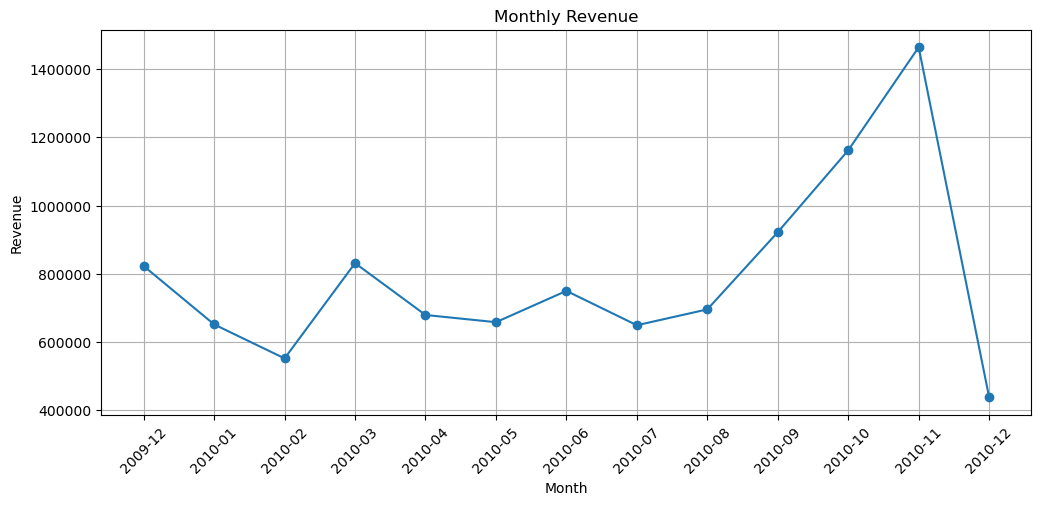

In [33]:
# ПОСТРОИМ ГРАФИК ВЫРУЧКИ ПО МЕСЯЦАМ
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['Month'],
    monthly_sales['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.grid()

plt.show()

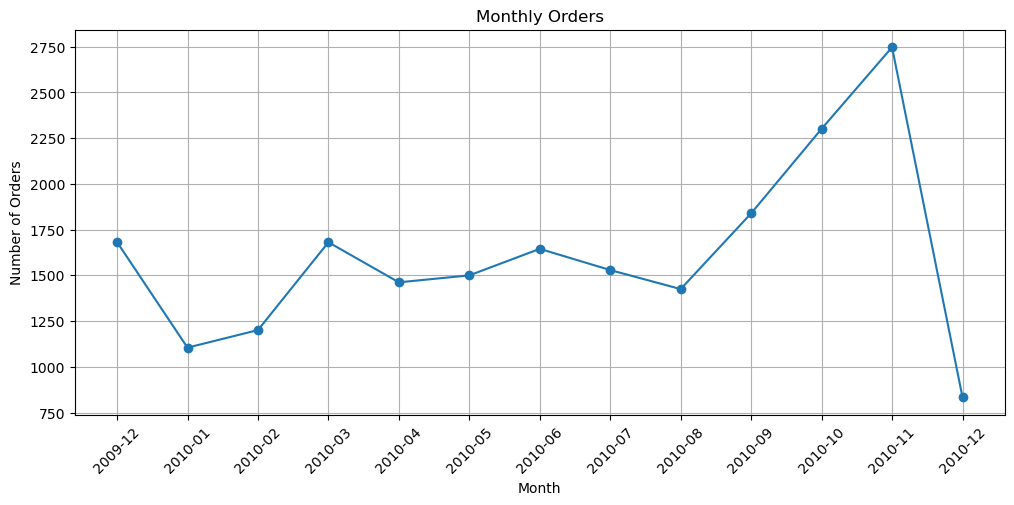

In [34]:
# ПОСТРОИМ ГРАФИК КОЛИЧЕСТВА ЗАКАЗОВ ПО МЕСЯЦАМ
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['Month'],
    monthly_sales['Orders'],
    marker='o'
)

plt.title('Monthly Orders')
plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.grid()

plt.show()


**Выводы:**

- Наибольшая выручка зафиксирована в ноябре 2010 года.
- С сентября по ноябрь наблюдается устойчивый рост выручки и количества заказов.
- Рост может быть связан с сезонным увеличением спроса перед рождественскими праздниками. Однако для подтверждения этой гипотезы необходим дополнительный анализ.
- Декабрь представлен данными только по 9 число, поэтому его нельзя напрямую сравнивать с полными месяцами.


### 2.3. Анализ продаж по странам

In [35]:
country_sales = sales_clean.groupby('Country').agg(
    Revenue=('TotalPrice', 'sum'),
    Orders=('Invoice', 'nunique')
).sort_values(by='Revenue', ascending=False)

country_sales.head(10)

,Revenue,Orders
Country,,
United Kingdom,8812311.833,19290
EIRE,380909.570,348
Netherlands,268784.350,135
Germany,202025.391,347
France,147103.140,241
Sweden,53501.990,69
Denmark,50906.850,26
Spain,47568.650,66
Switzerland,43921.390,40


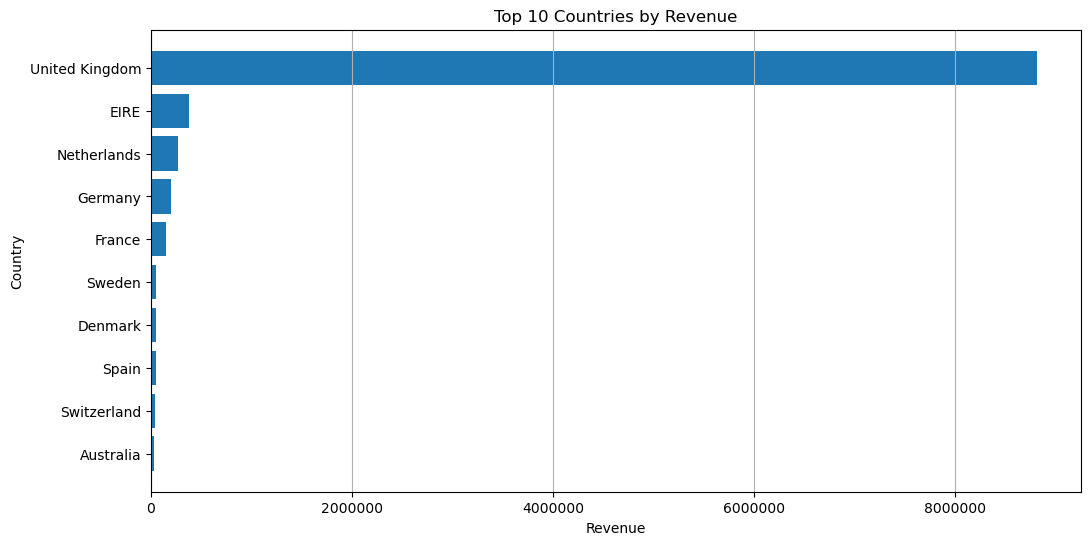

In [36]:
top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

plt.barh(top_countries.index, top_countries['Revenue'])
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.gca().invert_yaxis()

plt.ticklabel_format(axis='x', style='plain')
plt.grid(axis='x')

plt.show()


**Выводы:**

- Основная часть выручки (около 85,8%) приходится на Великобританию.
- Среди зарубежных рынков лидируют Ирландия, Нидерланды и Германия.
- Выручка от продаж в Ирландии почти вдвое выше, чем в Германии, при практически одинаковом количестве заказов.


### 2.4. Анализ продаж по товарам 

In [37]:
# ИСКЛЮЧИМ СЛУЖЕБНЫЕ ПОЗИЦИИ И ВЫВЕДИМ ТОВАРЫ С НАИБОЛЬШЕЙ ВЫРУЧКОЙ
non_product_items = [
    'Manual',
    'DOTCOM POSTAGE',
    'POSTAGE',
    'AMAZON FEE',
    'Bank Charges'
]

product_sales = sales_clean[
    ~sales_clean['Description'].isin(non_product_items)
].groupby('Description').agg(
    Revenue=('TotalPrice', 'sum'),
    Quantity=('Quantity', 'sum')
).sort_values(by='Revenue', ascending=False)

top_products = product_sales.head(10)
top_products

,Revenue,Quantity
Description,,
REGENCY CAKESTAND 3 TIER,169912.76,13685
WHITE HANGING HEART T-LIGHT HOLDER,160345.63,58691
ASSORTED COLOUR BIRD ORNAMENT,72890.19,45228
PAPER CHAIN KIT 50'S CHRISTMAS,58127.30,17205
JUMBO BAG RED RETROSPOT,56480.46,30746
PARTY BUNTING,49664.12,10079
ROTATING SILVER ANGELS T-LIGHT HLDR,47954.49,23037
EDWARDIAN PARASOL NATURAL,36925.26,7469
JUMBO BAG STRAWBERRY,36732.16,20002


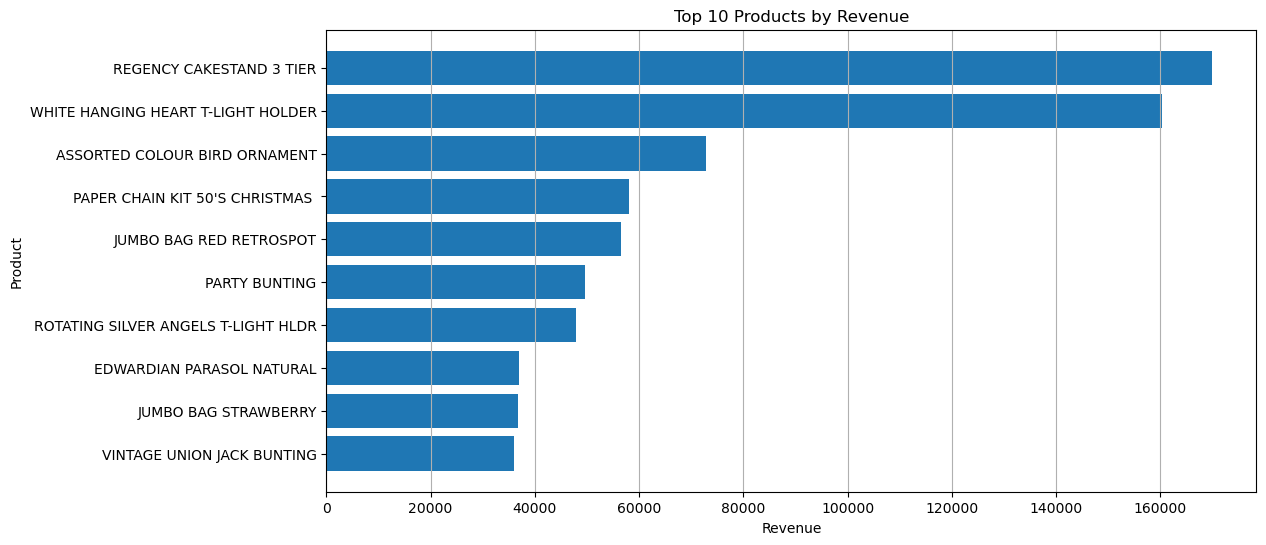

In [38]:
top_products = product_sales.head(10)

plt.figure(figsize=(12, 6))

plt.barh(top_products.index, top_products['Revenue'])

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.gca().invert_yaxis()
plt.ticklabel_format(axis='x', style='plain')
plt.grid(axis='x')

plt.show()

**Выводы:**

- Среди товаров с наибольшей выручкой преобладают товары для дома и праздничного оформления.
- Служебные позиции исключены из рейтинга, чтобы анализировать именно товарный ассортимент.

## 3. RFM-анализ покупателей

### 3.1. Расчёт RFM-показателей

In [39]:
# ОПРЕДЕЛЯЕМ ДАТУ АНАЛИЗА
snapshot_date = (
    rfm_data['InvoiceDate'].max().normalize()
    + pd.Timedelta(days=1)
)

# РАССЧИТЫВАЕМ RFM
rfm = rfm_data.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (
        snapshot_date - x.max().normalize()
    ).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum')
)

In [40]:
rfm.describe()

,Recency,Frequency,Monetary
count,4312.000000,4312.000000,4312.000000
mean,91.172542,4.455705,2040.406712
std,96.861457,8.170213,8911.755977
min,1.000000,1.000000,2.950000
25%,18.000000,1.000000,307.187500
50%,53.000000,2.000000,701.615000
75%,136.000000,5.000000,1714.932500
max,374.000000,205.000000,349164.350000


In [41]:
rfm['Frequency'].value_counts().head(10)

Frequency
1     1419
2      810
3      525
4      378
5      238
6      192
7      157
8      109
9       80
10      69
Name: count, dtype: int64

### 3.2. Присвоение RFM-оценок

Для Frequency использовано разделение на четыре диапазона:

- 1 заказ — оценка 1;
- 2–3 заказа — оценка 2;
- 4–7 заказов — оценка 3;
- 8 и более заказов — оценка 4.

Такой подход выбран из-за большого количества покупателей, совершивших только одну покупку. Границы являются выбранными для данного проекта правилами сегментации, а не универсальным стандартом.

In [42]:
# R: ЧЕМ МЕНЬШЕ ДНЕЙ С ПОСЛЕДНЕЙ ПОКУПКИ, ТЕМ ВЫШЕ ОЦЕНКА
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    4,
    labels=[4, 3, 2, 1]
)

# F: ОЦЕНКА В ЗАВИСИМОСТИ ОТ КОЛИЧЕСТВА ЗАКАЗОВ
rfm['F_Score'] = pd.cut(
    rfm['Frequency'],
    bins=[0, 1, 3, 7, float('inf')],
    labels=[1, 2, 3, 4]
)

# M: ЧЕМ БОЛЬШЕ ПОТРАЧЕНО ДЕНЕГ, ТЕМ ВЫШЕ ОЦЕНКА
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'],
    4,
    labels=[1, 2, 3, 4]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
Customer ID,,,,,,
12346,165,11,372.86,1,4,2
12347,3,2,1323.32,4,2,3
12348,74,1,222.16,2,1,1
12349,43,3,2671.14,3,2,4
12351,11,1,300.93,4,1,1


In [43]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346,165,11,372.86,1,4,2,142
12347,3,2,1323.32,4,2,3,423
12348,74,1,222.16,2,1,1,211
12349,43,3,2671.14,3,2,4,324
12351,11,1,300.93,4,1,1,411


### 3.3. Сегментация покупателей

In [44]:
def segment_customer(row):
    r = int(row['R_Score'])
    f = int(row['F_Score'])
    m = int(row['M_Score'])

    if r >= 3 and f >= 3 and m >= 3:
        return 'Champions'
    elif r >= 2 and f >= 3:
        return 'Loyal Customers'
    elif r == 4 and f == 1:
        return 'New Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    else:
        return 'Hibernating'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

rfm['Segment'].value_counts()

Segment
Hibernating            1726
Champions              1106
Potential Loyalists     911
Loyal Customers         366
New Customers           117
At Risk                  86
Name: count, dtype: int64

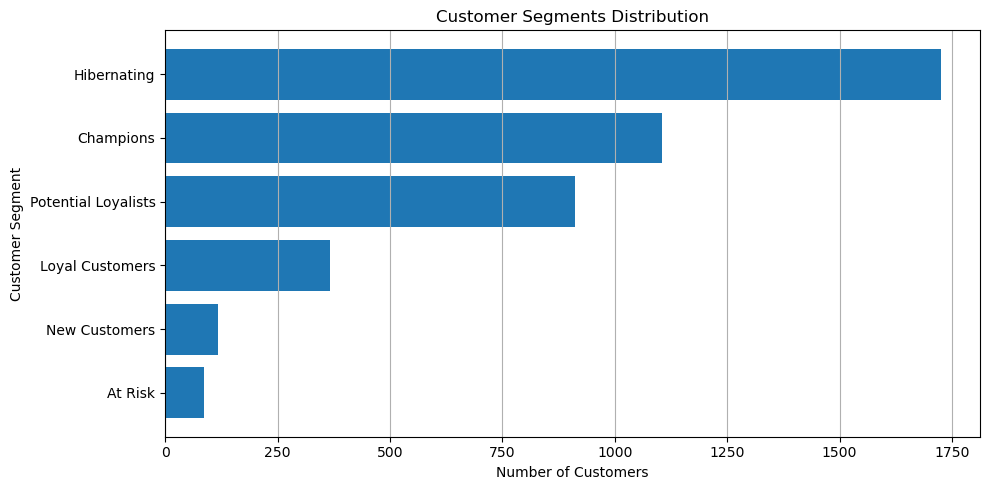

In [45]:
segment_counts = rfm['Segment'].value_counts()

plt.figure(figsize=(10, 5))

plt.barh(segment_counts.index, segment_counts.values)

plt.title('Customer Segments Distribution')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.gca().invert_yaxis()
plt.grid(axis='x')

plt.tight_layout()
plt.show()

## 4. Общие выводы

### Результаты исследования продаж

- Общая выручка составила около 10,27 млн.
- Основная часть выручки (85,8%) приходится на Великобританию.
- Наибольшая выручка зафиксирована в ноябре 2010 года.
- Среди товаров лидируют товары для дома и праздничного оформления.

### Результаты RFM-анализа

- 40% покупателей относятся к сегменту Hibernating.
- 25,6% покупателей относятся к Champions.
- 21,1% составляют Potential Loyalists.

### Возможные бизнес-рекомендации

- Разработать кампании по возвращению покупателей из сегмента Hibernating.
- Поддерживать лояльность Champions с помощью специальных предложений.
- Стимулировать Potential Loyalists к повторным покупкам.